In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns # statistical data visualization
%matplotlib inline
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix
from sklearn import metrics
from sklearn.metrics import classification_report


In [ ]:
df = pd.read_excel("Obesity_Dataset.xlsx")

In [ ]:
df.head()

,Sex,Age,Height,Overweight_Obese_Family,Consumption_of_Fast_Food,Frequency_of_Consuming_Vegetables,Number_of_Main_Meals_Daily,Food_Intake_Between_Meals,Smoking,Liquid_Intake_Daily,Calculation_of_Calorie_Intake,Physical_Excercise,Schedule_Dedicated_to_Technology,Type_of_Transportation_Used,Class
0,2,18,155,2,2,3,1,3,2,1,2,3,3,4,2
1,2,18,158,2,2,3,1,1,2,1,2,1,3,3,2
2,2,18,159,2,2,2,1,3,2,3,2,2,3,4,2
3,2,18,162,2,2,2,2,2,2,2,2,1,3,4,2
4,2,18,165,2,1,2,1,3,2,1,2,3,3,2,2


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1610 entries, 0 to 1609
Data columns (total 15 columns):
 #   Column                             Non-Null Count  Dtype
---  ------                             --------------  -----
 0   Sex                                1610 non-null   int64
 1   Age                                1610 non-null   int64
 2   Height                             1610 non-null   int64
 3   Overweight_Obese_Family            1610 non-null   int64
 4   Consumption_of_Fast_Food           1610 non-null   int64
 5   Frequency_of_Consuming_Vegetables  1610 non-null   int64
 6   Number_of_Main_Meals_Daily         1610 non-null   int64
 7   Food_Intake_Between_Meals          1610 non-null   int64
 8   Smoking                            1610 non-null   int64
 9   Liquid_Intake_Daily                1610 non-null   int64
 10  Calculation_of_Calorie_Intake      1610 non-null   int64
 11  Physical_Excercise                 1610 non-null   int64
 12  Schedule_Dedicated_t

In [ ]:
df['Class'].unique()

array([2, 3, 4, 1])

In [ ]:
X = df.drop(['Class'], axis=1)
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.30, random_state = 42)

In [ ]:
rfc = RandomForestClassifier(n_estimators=1000, random_state=0) #dibiarkan default untuk parameter lainnya



# fit the model
rfc.fit(X_train, y_train)

# Predict the Test set results
y_pred = rfc.predict(X_test)

# Check accuracy score
from sklearn.metrics import accuracy_score

print('Model accuracy score with 1000 decision-trees : {0:0.4f}'.
      format(accuracy_score(y_test, y_pred)))

Model accuracy score with 1000 decision-trees : 0.8406


In [ ]:
feature_scores = pd.Series(rfc.feature_importances_,
                           index=X_train.columns).sort_values(ascending=False)

feature_scores

,0
Age,0.230871
Height,0.112971
Frequency_of_Consuming_Vegetables,0.094501
Number_of_Main_Meals_Daily,0.083029
Physical_Excercise,0.078034
Type_of_Transportation_Used,0.073603
Food_Intake_Between_Meals,0.056190
Liquid_Intake_Daily,0.050844
Sex,0.047531
Smoking,0.046257


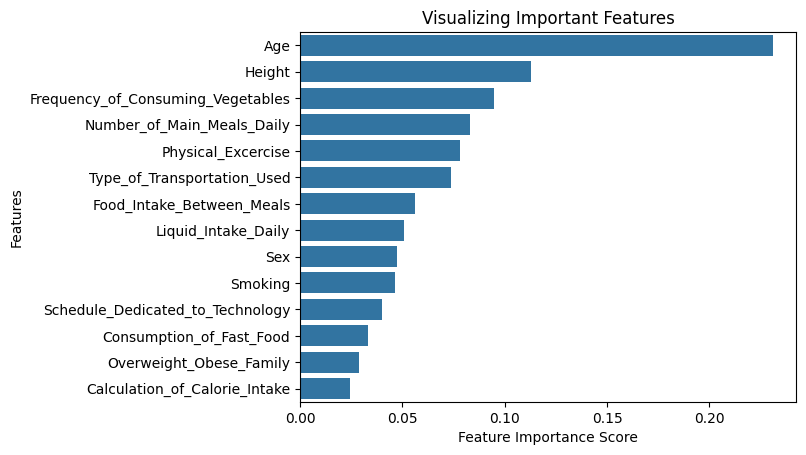

In [ ]:
sns.barplot(x=feature_scores, y=feature_scores.index)

plt.xlabel('Feature Importance Score')
plt.ylabel('Features')
plt.title("Visualizing Important Features")
plt.show()

In [ ]:
X = df.drop(['Class', 'Calculation_of_Calorie_Intake', 'Overweight_Obese_Family', 'Consumption_of_Fast_Food', 'Schedule_Dedicated_to_Technology', 'Smoking', 'Sex', 'Liquid_Intake_Daily', 'Food_Intake_Between_Meals', 'Type_of_Transportation_Used'], axis=1) #drop fitur class dan doors
y = df['Class']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.30, random_state = 42)

In [ ]:
clf = RandomForestClassifier(n_estimators=1000,random_state=0)

clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

print('Model accuracy score with selested features : {0:0.4f}'.
      format(accuracy_score(y_test, y_pred)))

Model accuracy score with selested features : 0.8240


Text(0.5, 23.52222222222222, 'Predicted label')

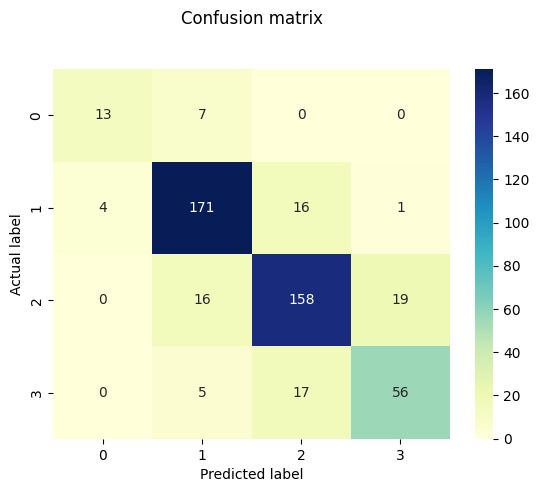

In [ ]:
confusion_matrix(y_test,y_pred)
cnf_matrix = metrics.confusion_matrix(y_test, y_pred)

p = sns.heatmap(pd.DataFrame(cnf_matrix), annot=True, cmap="YlGnBu" ,fmt='g')
plt.title('Confusion matrix', y=1.1)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')

In [ ]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           1       0.76      0.65      0.70        20
           2       0.86      0.89      0.87       192
           3       0.83      0.82      0.82       193
           4       0.74      0.72      0.73        78

    accuracy                           0.82       483
   macro avg       0.80      0.77      0.78       483
weighted avg       0.82      0.82      0.82       483

